In [7]:
# Core libraries for financial data analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

print("QQQ project environment is ready!")

QQQ project environment is ready!


In [1]:
import yfinance as yf

# Download daily historical QQQ data
qqq = yf.Ticker("QQQ").history(
    start="2010-01-01",
    end="2026-09-02",
    interval="1d",
    auto_adjust=True,
    actions=False
)

# Display the first five rows
qqq.head()

,Open,High,Low,Close,Volume
Date,,,,,
2010-01-04 00:00:00-05:00,40.126708,40.265285,40.074741,40.204655,62822800
2010-01-05 00:00:00-05:00,40.178673,40.273945,39.979468,40.204655,62935600
2010-01-06 00:00:00-05:00,40.187336,40.317250,39.901520,39.962147,96033000
2010-01-07 00:00:00-05:00,40.022789,40.074757,39.771617,39.988144,77094100
2010-01-08 00:00:00-05:00,39.901526,40.317257,39.780272,40.317257,88886600


In [2]:
# Check the size of our dataset
print("Dataset shape:", qqq.shape)

# Check the first and last trading dates
print("First trading day:", qqq.index.min())
print("Last trading day:", qqq.index.max())

# Display the last five observations
qqq.tail()

Dataset shape: (4191, 5)
First trading day: 2010-01-04 00:00:00-05:00
Last trading day: 2026-09-01 00:00:00-04:00


,Open,High,Low,Close,Volume
Date,,,,,
2026-08-26 00:00:00-04:00,707.672576,712.277823,707.233031,710.629517,20392400
2026-08-27 00:00:00-04:00,716.183733,720.599115,713.786268,720.359375,28723500
2026-08-28 00:00:00-04:00,718.990817,723.376262,714.345694,715.684265,34105400
2026-08-31 00:00:00-04:00,714.425544,716.833070,712.417627,716.013916,32237200
2026-09-01 00:00:00-04:00,706.653642,711.558504,703.926442,706.903381,35236100


In [3]:
# Check for missing values in each column
print("Missing values:")
print(qqq.isna().sum())

# Check for duplicate trading dates
print("Duplicate dates:", qqq.index.duplicated().sum())

# Check whether dates are in chronological order
print("Chronological order:", qqq.index.is_monotonic_increasing)

Missing values:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicate dates: 0
Chronological order: True


In [4]:
# Calculate daily percentage returns
qqq["Daily_Return_Pct"] = qqq["Close"].pct_change() * 100

# Display closing prices alongside returns
qqq[["Close", "Daily_Return_Pct"]].head(10)


,Close,Daily_Return_Pct
Date,,
2010-01-04 00:00:00-05:00,40.204655,NaN
2010-01-05 00:00:00-05:00,40.204655,0.000000
2010-01-06 00:00:00-05:00,39.962147,-0.603184
2010-01-07 00:00:00-05:00,39.988144,0.065054
2010-01-08 00:00:00-05:00,40.317257,0.823026
2010-01-11 00:00:00-05:00,40.152710,-0.408130
2010-01-12 00:00:00-05:00,39.650341,-1.251146
2010-01-13 00:00:00-05:00,40.144032,1.245110
2010-01-14 00:00:00-05:00,40.178673,0.086292


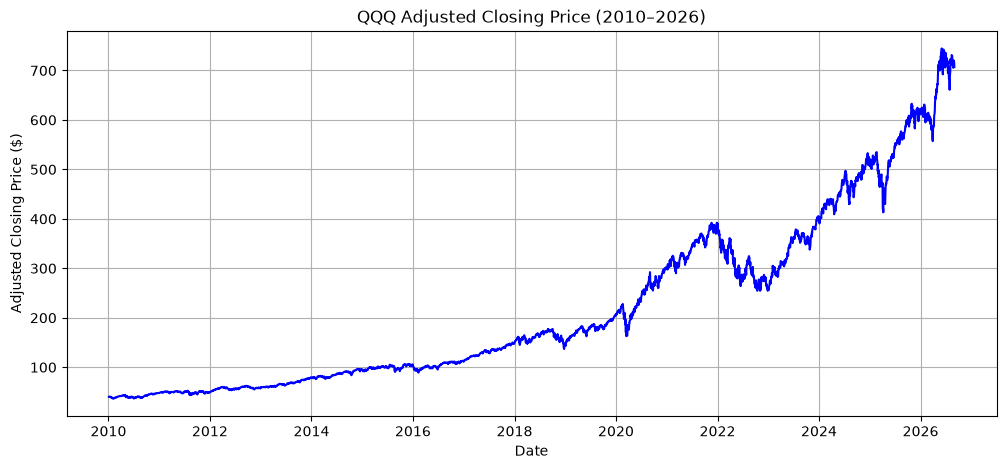

In [7]:
import matplotlib.pyplot as plt

# Create the figure
plt.figure(figsize=(12, 5))

# Plot QQQ's adjusted closing prices
plt.plot(qqq.index, qqq["Close"], color="blue")

# Add labels and a title
plt.title("QQQ Adjusted Closing Price (2010–2026)")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price ($)")

# Add gridlines and display the graph
plt.grid(True)
plt.show()


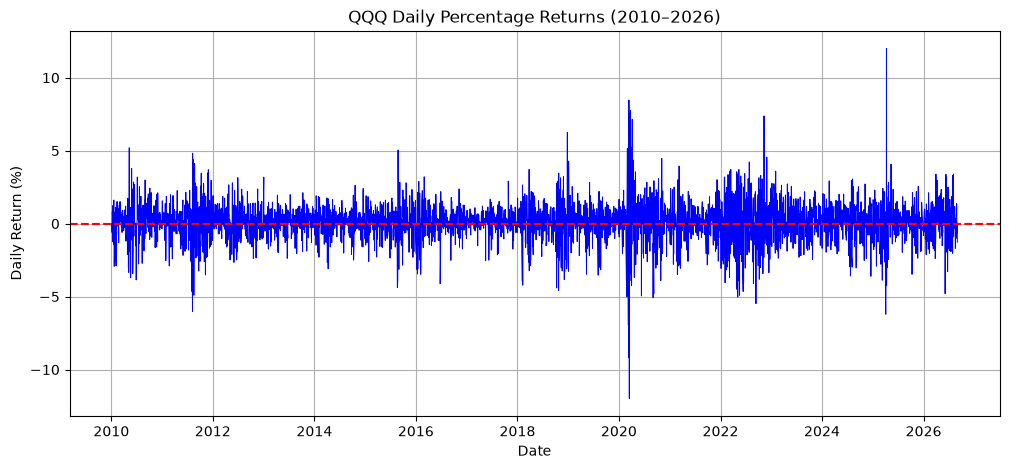

In [ ]:
# Create the figure
plt.figure(figsize=(12, 5))

# Plot daily percentage returns
plt.plot(qqq.index, qqq["Daily_Return_Pct"],
         color="blue", linewidth=0.7)

# Add a horizontal line at 0%
plt.axhline(y=0, color="red", linestyle="--")

# Add labels and title
plt.title("QQQ Daily Percentage Returns (2010–2026)")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")

# Display the graph
plt.grid(True)
plt.show()

In [9]:
# Calculate summary statistics for daily returns
qqq["Daily_Return_Pct"].describe()

count    4190.000000
mean        0.076932
std         1.301714
min       -11.978787
25%        -0.482203
50%         0.117372
75%         0.742176
max        12.003069
Name: Daily_Return_Pct, dtype: float64

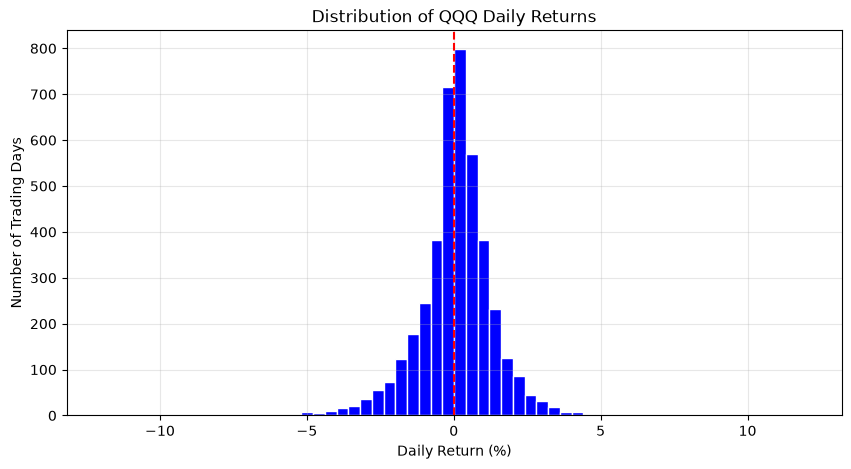

In [10]:
# Remove the first missing return
returns = qqq["Daily_Return_Pct"].dropna()

# Create a histogram
plt.figure(figsize=(10, 5))
plt.hist(returns, bins=60, color="blue", edgecolor="white")

# Add a reference line at zero
plt.axvline(x=0, color="red", linestyle="--")

# Add labels
plt.title("Distribution of QQQ Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Number of Trading Days")

plt.grid(True, alpha=0.3)
plt.show()

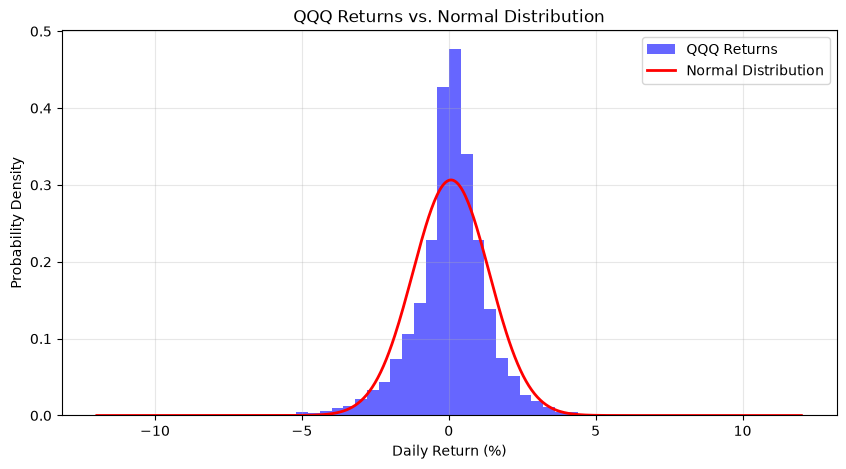

In [11]:
import numpy as np
from scipy.stats import norm

# Calculate the mean and standard deviation
mean_return = returns.mean()
std_return = returns.std()

# Create x-values for the normal curve
x = np.linspace(returns.min(), returns.max(), 500)

# Plot the histogram as a probability density
plt.figure(figsize=(10, 5))
plt.hist(returns, bins=60, density=True,
         color="blue", alpha=0.6, label="QQQ Returns")

# Overlay the normal distribution
plt.plot(x, norm.pdf(x, mean_return, std_return),
         color="red", linewidth=2, label="Normal Distribution")

plt.title("QQQ Returns vs. Normal Distribution")
plt.xlabel("Daily Return (%)")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [12]:
# Calculate standardized returns (z-scores)
z_scores = (returns - returns.mean()) / returns.std()

# Identify days more than 3 standard deviations from the mean
extreme_days = z_scores.abs() > 3

# Count and calculate the percentage of extreme days
print("Extreme trading days:", extreme_days.sum())
print("Percentage of days:", extreme_days.mean() * 100)

Extreme trading days: 61
Percentage of days: 1.4558472553699284


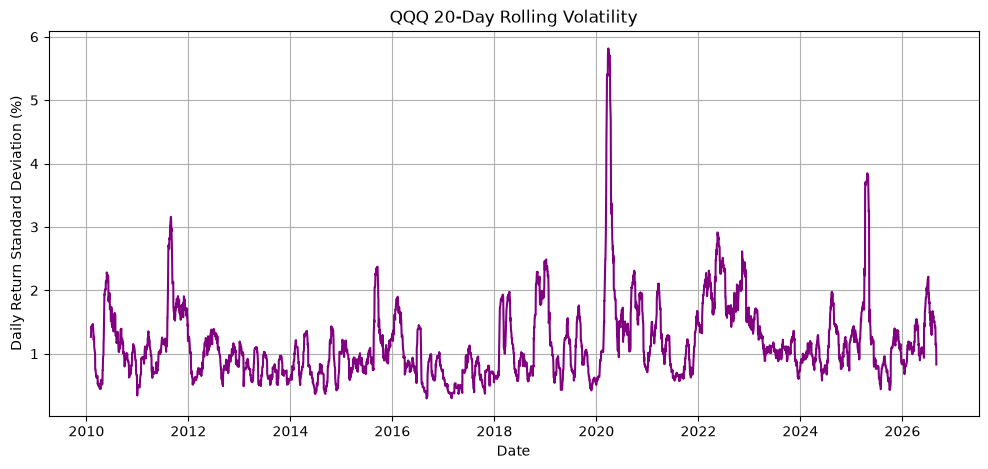

In [13]:
# Calculate rolling 20-day volatility
rolling_volatility = qqq["Daily_Return_Pct"].rolling(window=20).std()

# Plot volatility over time
plt.figure(figsize=(12, 5))
plt.plot(qqq.index, rolling_volatility, color="purple")

plt.title("QQQ 20-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Daily Return Standard Deviation (%)")

plt.grid(True)
plt.show()
